# Assignment 5: Predicting PM2.5 air quality from meteorology with random forests

Fine particulate matter (**PM2.5**) is the air pollutant responsible for the largest
global health burden. It penetrates deep into the lungs and enters the bloodstream, and
long-term exposure is linked to cardiovascular and respiratory disease. Regulatory networks
measure it directly, but direct measurement is expensive and sparse, so a recurring question
in air quality science is how much of the day-to-day variation can be explained by
**meteorology** and by other, more cheaply measured pollutants.

That is the question you will attack here, with decision trees and random forests. Pollution
concentrations are set by the balance between emissions and the atmosphere's ability to
disperse them, and the dispersion side is meteorological: wind ventilates, a deep mixing
layer dilutes, humidity drives secondary particle formation, temperature controls both
chemistry and the stability of the boundary layer. These relationships are strongly
**nonlinear** and full of **interactions**: which is exactly what trees are good at and
what a linear model handles badly.

You will use **real measurements from the US EPA Air Quality System** for 2022. Every number in this notebook is an instrument
reading from a regulatory monitor.

Answer each numbered question in the empty cell below it.

In [1]:
import io
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Load the data

EPA publishes pre-generated annual files, one per measured parameter, with no API key
required. We need six of them: PM2.5 (our target), plus temperature, wind, relative
humidity, ozone and nitrogen dioxide as predictors. The wind file gives both speed and
direction. Together they are about 27 MB.

Different parameters are measured at different monitoring sites, so the files cannot be
joined at site level without discarding most of the data. We aggregate each one to a
**county-day** mean and join on that. The resulting unit of analysis is "one county on one
day".

In [2]:
BASE = "https://aqs.epa.gov/aqsweb/airdata/"

def load_epa(filename, parameter_code, usecols):
    """Download one EPA annual file and return one parameter from it as a dataframe."""
    with urllib.request.urlopen(BASE + filename + ".zip") as resp:
        archive = zipfile.ZipFile(io.BytesIO(resp.read()))
    df = pd.read_csv(archive.open(archive.namelist()[0]),
                     usecols=usecols + ["Parameter Code"], low_memory=False)
    df = df[df["Parameter Code"] == parameter_code]
    df["Date Local"] = pd.to_datetime(df["Date Local"])
    return df

KEY = ["State Code", "County Code", "Date Local"]

# PM2.5 -- the target. We keep the AQI column too; it is the official index value.
pm = load_epa("daily_88101_2022", 88101,
              KEY + ["Arithmetic Mean", "AQI", "Latitude", "Longitude",
                     "State Name", "County Name"])
print(f"{len(pm):,} PM2.5 site-days")

data = (pm.groupby(KEY)
          .agg(pm25=("Arithmetic Mean", "mean"), AQI=("AQI", "max"),
               lat=("Latitude", "mean"), lon=("Longitude", "mean"),
               state=("State Name", "first"), county=("County Name", "first"))
          .reset_index())
print(f"{len(data):,} PM2.5 county-days")

# Predictors. Some files hold more than one parameter (the wind file has both speed and
# direction), so each is filtered to one parameter code, then aggregated to the county-day
# mean and joined on.
for filename, code, column in [("daily_TEMP_2022", 62101, "temp"),
                               ("daily_WIND_2022", 61103, "wind"),
                               ("daily_WIND_2022", 61104, "wdir"),
                               ("daily_RH_DP_2022", 62201, "rh"),
                               ("daily_44201_2022", 44201, "o3"),
                               ("daily_42602_2022", 42602, "no2")]:
    d = load_epa(filename, code, KEY + ["Arithmetic Mean"])
    d = d.groupby(KEY)["Arithmetic Mean"].mean().reset_index().rename(
        columns={"Arithmetic Mean": column})
    data = data.merge(d, on=KEY, how="inner")
    print(f"  after joining {column:<5} {len(data):>7,} rows")

data["doy"] = data["Date Local"].dt.dayofyear
data.head()


863,466 PM2.5 site-days
195,243 PM2.5 county-days
  after joining temp  123,822 rows
  after joining wind   81,223 rows
  after joining wdir   79,764 rows
  after joining rh     55,309 rows
  after joining o3     48,331 rows
  after joining no2    31,729 rows


,State Code,County Code,Date Local,pm25,AQI,lat,lon,state,county,temp,wind,wdir,rh,o3,no2,doy
0,1,73,2022-01-02,2.000000,11.0,33.499722,-86.924167,Alabama,Jefferson,54.995834,14.648295,137.041667,68.625000,0.017824,1.937500,2
1,1,73,2022-01-05,8.557143,52.0,33.499371,-86.801342,Alabama,Jefferson,47.906250,8.366667,105.520833,61.375000,0.012563,15.660764,5
2,1,73,2022-01-08,6.700000,41.0,33.524735,-86.861093,Alabama,Jefferson,44.922917,10.533333,70.625000,48.875000,0.031000,8.158333,8
3,1,73,2022-01-11,3.971429,27.0,33.499371,-86.801342,Alabama,Jefferson,41.116667,7.635000,67.800000,41.916667,0.017647,11.174653,11
4,1,73,2022-01-14,7.966667,52.0,33.524735,-86.861093,Alabama,Jefferson,42.946162,6.409320,84.649123,52.083333,0.004455,16.922478,14


The columns are:

| Column | Meaning | Units |
| --- | --- | --- |
| `pm25` | daily mean PM2.5: **the regression target** | µg/m³ |
| `AQI` | official Air Quality Index for PM2.5 | index |
| `temp` | daily mean temperature | °F |
| `wind` | daily mean wind speed | knots |
| `wdir` | daily mean wind direction | degrees compass |
| `rh` | daily mean relative humidity | % |
| `o3` | daily mean ozone | ppm |
| `no2` | daily mean nitrogen dioxide | ppb |
| `lat`, `lon` | county monitor location | degrees |
| `doy` | day of the year | 1–365 |

```{admonition} A note on what this model can and cannot be
:class: note
Ozone and NO2 are *pollutants*, not meteorology. They are included because they carry
information about the state of the atmosphere and about local emissions, and because they
are measured on the same network. But be careful about what that means: a model using NO2
to predict PM2.5 is not a physical model of particle formation, it is exploiting the fact
that both respond to traffic emissions and to the same dispersion conditions. Keep that in
mind when you interpret the feature importances in question 13.
```

## Part 1: Data exploration

1. How many county-days are in the merged dataset, what date range does it cover, and how many distinct states are represented?

In [3]:
print(f"County-days: {len(data)} county-days")

min_date_2 = data['Date Local'].dt.date.min()
max_date_2 = data['Date Local'].dt.date.max()
print(f"Date range: {min_date_2}, {max_date_2}")

print(f"Number of distinct states: {data['State Code'].nunique()} states")

County-days: 31729 county-days
Date range: 2022-01-01, 2022-12-31
Number of distinct states: 42 states


2. Check whether there are any NaNs in the dataframe. If there are, say which columns they are in and drop those rows.

In [4]:
data.isna().sum()

State Code       0
County Code      0
Date Local       0
pm25             0
AQI            155
lat              0
lon              0
state            0
county           0
temp             0
wind             0
wdir             0
rh               0
o3               0
no2              0
doy              0
dtype: int64

_There are NaNs in the AQI column._

In [5]:
data_cleaned = data.dropna().copy()
data_cleaned.head()

,State Code,County Code,Date Local,pm25,AQI,lat,lon,state,county,temp,wind,wdir,rh,o3,no2,doy
0,1,73,2022-01-02,2.000000,11.0,33.499722,-86.924167,Alabama,Jefferson,54.995834,14.648295,137.041667,68.625000,0.017824,1.937500,2
1,1,73,2022-01-05,8.557143,52.0,33.499371,-86.801342,Alabama,Jefferson,47.906250,8.366667,105.520833,61.375000,0.012563,15.660764,5
2,1,73,2022-01-08,6.700000,41.0,33.524735,-86.861093,Alabama,Jefferson,44.922917,10.533333,70.625000,48.875000,0.031000,8.158333,8
3,1,73,2022-01-11,3.971429,27.0,33.499371,-86.801342,Alabama,Jefferson,41.116667,7.635000,67.800000,41.916667,0.017647,11.174653,11
4,1,73,2022-01-14,7.966667,52.0,33.524735,-86.861093,Alabama,Jefferson,42.946162,6.409320,84.649123,52.083333,0.004455,16.922478,14


In [6]:
data_cleaned.isna().sum()

State Code     0
County Code    0
Date Local     0
pm25           0
AQI            0
lat            0
lon            0
state          0
county         0
temp           0
wind           0
wdir           0
rh             0
o3             0
no2            0
doy            0
dtype: int64

3. Make a histogram of each of the numerical variables. Comment on the shape of the `pm25` distribution in particular, is it symmetric?

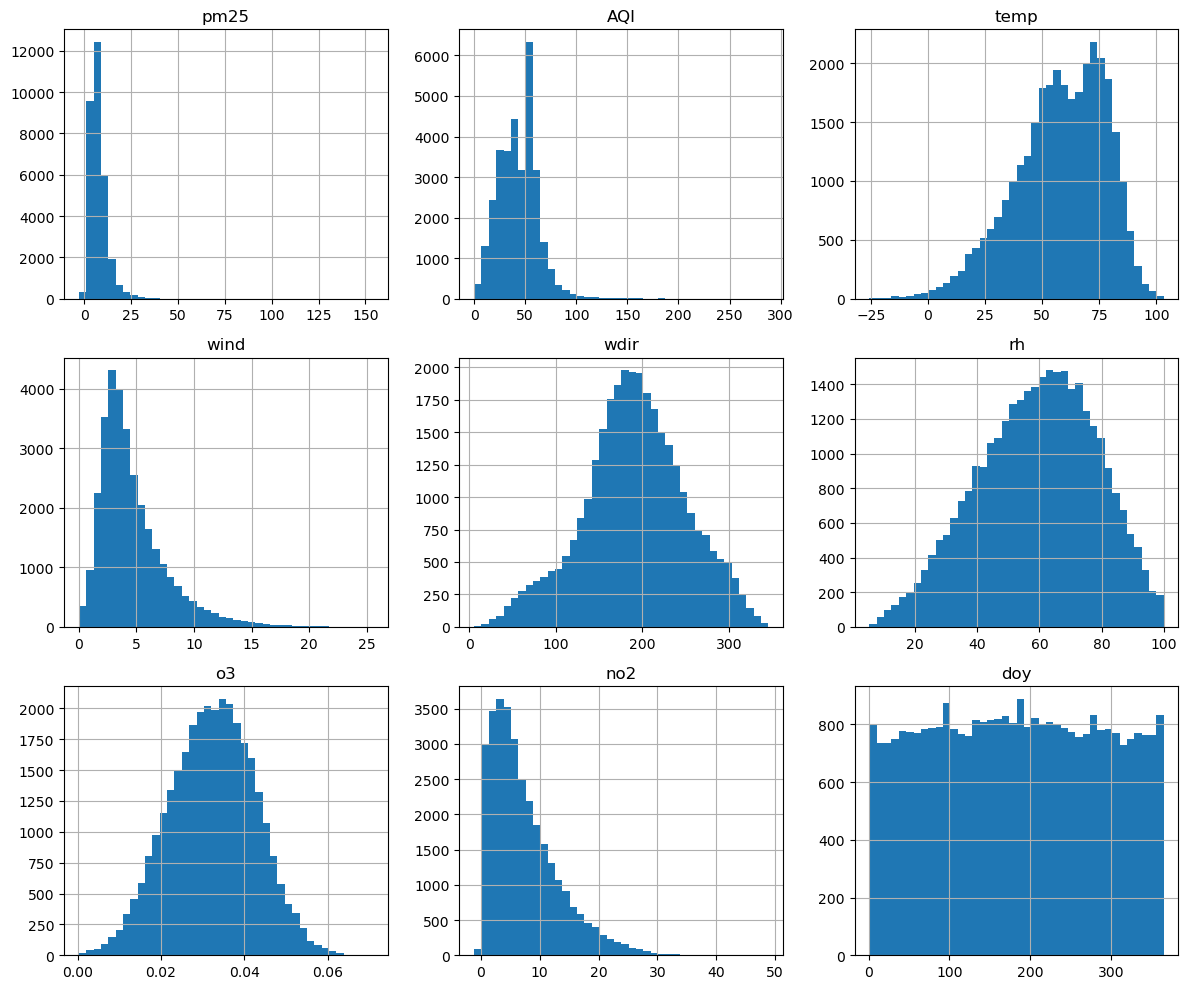

In [7]:
import matplotlib.pyplot as plt

# 1. Plot histograms for all numerical columns automatically
data_cleaned.hist(column=['pm25','AQI','temp','wind','wdir','rh','o3','no2','doy'],bins=40, figsize=(12, 10))

# 2. Adjust layout so titles and labels don't overlap
plt.tight_layout()

# 3. Show the grid of plots
plt.show()

_The PM 2.5 column is not symmetric. It appears to be right-skewed, with more occurrences of days with lower AQI values and fewer occurrences of days with higher AQI values._

4. There are two targets. The numerical one is `pm25`, the daily mean concentration. The
categorical one is the **AQI category**, the band the EPA reports to the public, which is
derived from the AQI value by these breakpoints:

| Category | AQI range | Label |
| --- | --- | --- |
| 0 | 0–50 | Good |
| 1 | 51–100 | Moderate |
| 2 | 101–150 | Unhealthy for Sensitive Groups |
| 3 | 151+ | Unhealthy or worse |

The EPA splits the top band further (Unhealthy, Very Unhealthy, Hazardous), but those days
are so rare in 2022 that we merge them into one category.

Create a NumPy array `y_regression` containing `pm25`, and a NumPy array
`y_classification` containing the AQI category computed from the `AQI` column.

In [8]:
y_regression = np.array(data_cleaned['pm25'])
data_cleaned["AQI Category"] = np.select([data_cleaned.AQI >=151, data_cleaned.AQI >=101 , data_cleaned.AQI >= 51, data_cleaned.AQI >=0],["Very Unhealthy", "Unhealthy","Moderate","Good"], default = "Very Good")

y_classification = np.array(data_cleaned["AQI Category"])
print(f'Y Regression shape: {y_regression.shape}')
print(f'Y Classification shape: {y_classification.shape}')

Y Regression shape: (31574,)
Y Classification shape: (31574,)


5. Check how balanced the four classes are. Report the count and the percentage in each.

In [9]:
y_class_df = pd.Series(y_classification)
percentages = y_class_df.value_counts(normalize=True).values * 100
rounded_percentages = percentages.round(2)

table_counts = pd.DataFrame({'Class': y_class_df.value_counts().index,
                             'Count': y_class_df.value_counts().values,
                             'Percentage (%)': rounded_percentages})

table_counts

,Class,Count,Percentage (%)
0,Good,19028,60.26
1,Moderate,12316,39.01
2,Unhealthy,194,0.61
3,Very Unhealthy,36,0.11


6. Create a NumPy array called `features` containing these nine predictors:
   - temp
   - wind
   - wdir
   - rh
   - o3
   - no2
   - doy
   - lat
   - lon


In [10]:
features = np.array(['temp','wind','wdir','rh','o3','no2','doy','lat','lon'])

## Part 2: Preprocessing

7. Create two Python lists: `classnames`, holding the four category labels in the order
given in question 4, and `featurenames`, holding the nine feature names in the order you
built them.

In [11]:
classnames = ["Very Unhealthy", "Unhealthy","Moderate","Good"]
featurenames = ['temp','wind','wdir','rh','o3','no2','doy','lat','lon']

8. Save `features` as a NumPy array `X`. Do not scale it. Last week's linear models
needed `StandardScaler` because the penalty and the gradient steps depend on the units of
each feature. A random forest does not: every split is a threshold on one feature, so
rescaling that feature moves the threshold and changes nothing about which rows go left
or right.


In [12]:
X = data_cleaned[features].values
X

array([[  54.9958335 ,   14.6482955 ,  137.0416665 , ...,    2.        ,
          33.499722  ,  -86.924167  ],
       [  47.90625   ,    8.3666665 ,  105.520833  , ...,    5.        ,
          33.49937057,  -86.80134157],
       [  44.922917  ,   10.5333335 ,   70.625     , ...,    8.        ,
          33.524735  ,  -86.861093  ],
       ...,
       [  14.15277767,    2.98472233,  178.513889  , ...,  363.        ,
          43.915408  , -110.8144115 ],
       [  18.37500033,    2.34722233,  166.77777767, ...,  364.        ,
          43.915408  , -110.8144115 ],
       [  22.15277767,    2.44166667,  180.30555533, ...,  365.        ,
          43.915408  , -110.8144115 ]])

## Part 3: Training, validation, and test split

9. Split the data into training, validation and test sets, with 80% for training and 10%
each for validation and testing. Carry both targets through the split. Use
`stratify=` on the classification target so the rare categories are represented in every
split, and explain in a comment why that matters here.

In [13]:
from sklearn.model_selection import train_test_split

(X_train, X_rest, y_reg_train,y_reg_rest,y_cls_train, y_cls_rest) = train_test_split(X, y_regression, y_classification,
                                                                                     test_size=0.2, random_state=42,
                                                                                     stratify=y_classification)
(X_val, X_test, y_reg_val, y_reg_test, y_cls_val, y_cls_test) = train_test_split(X_rest, y_reg_rest,y_cls_rest,
                                                                                 test_size=0.5, random_state=42,
                                                                                 stratify=y_cls_rest)

print(f"Train shapes: X={X_train.shape}, y_reg={y_reg_train.shape}, y_cls={y_cls_train.shape}")
print(f"Val shapes:   X={X_val.shape}, y_reg={y_reg_val.shape}, y_cls={y_cls_val.shape}")
print(f"Test shapes:  X={X_test.shape}, y_reg={y_reg_test.shape}, y_cls={y_cls_test.shape}")

Train shapes: X=(25259, 9), y_reg=(25259,), y_cls=(25259,)
Val shapes:   X=(3157, 9), y_reg=(3157,), y_cls=(3157,)
Test shapes:  X=(3158, 9), y_reg=(3158,), y_cls=(3158,)


_Representation of rare categories in every split (stratification) matters because it ensures that the training, validation, and test sets contain the same proportion of all AQI categories so the model learns patterns to detect each of those categories, and allows us to calculate reliable evaluation metrics for each category._

## Part 4: Train a random forest regressor

10. Train a `RandomForestRegressor` on the training set using the regression target, with 120 estimators and a maximum depth of 20.

In [14]:
from sklearn.ensemble import RandomForestRegressor
forest = RandomForestRegressor(n_estimators=120, random_state=42, max_depth=20).fit(X_train, y_reg_train)

11. Predict PM2.5 for the validation set and compute the coefficient of determination ($R^2$) between the true and predicted values. Also report the RMSE in µg/m³, and plot predicted against observed with a 1:1 line.

R^2 Score between the true and predicted PM2.5 values: 0.5850
RMSE between the true and predicted PM2.5 values: 3.4515 µg/m³


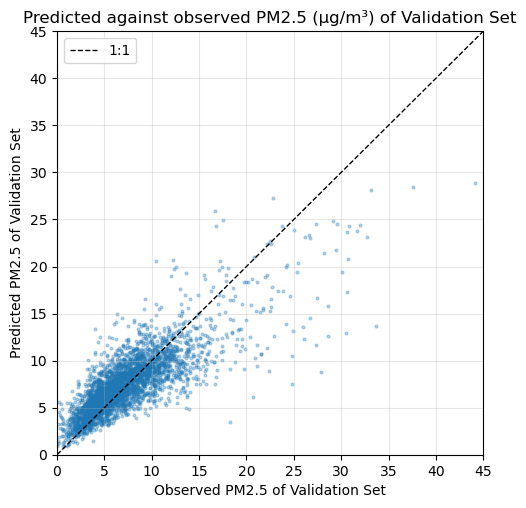

In [15]:
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

y_reg_val_pred = forest.predict(X_val)

def rmse(y, pred):
    return np.sqrt(mean_squared_error(y, pred))

val_r2 = r2_score(y_reg_val, y_reg_val_pred)
val_rmse = rmse(y_reg_val, y_reg_val_pred)

print(F"R^2 Score between the true and predicted PM2.5 values: {val_r2:.4f}")
print(F"RMSE between the true and predicted PM2.5 values: {val_rmse:.4f} µg/m³")

# plot
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(y_reg_val, y_reg_val_pred, s=4, alpha=0.3)
lims = [0,45]
ax.plot(lims,lims, "k--", lw=1, label="1:1")

ax.set_xlim(0, 45)
ax.set_ylim(0, 45)

ax.set_xlabel("Observed PM2.5 of Validation Set")
ax.set_ylabel("Predicted PM2.5 of Validation Set")
ax.set_title("Predicted against observed PM2.5 (µg/m³) of Validation Set")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

12. Make a bar plot of the feature importances of the trained regressor, with the x-axis labelled using `featurenames`.

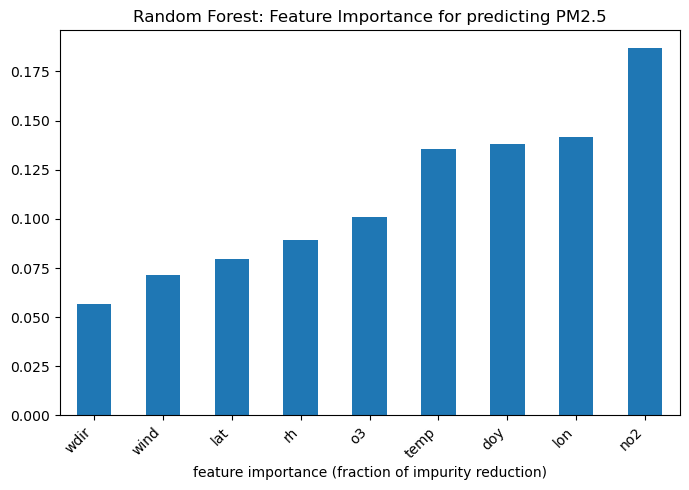

In [16]:
importance = pd.Series(forest.feature_importances_, index=featurenames).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
importance.head(15).iloc[::-1].plot.bar(ax=ax)
ax.set_xlabel("feature importance (fraction of impurity reduction)")
ax.set_title("Random Forest: Feature Importance for predicting PM2.5")
plt.xticks(rotation=45, ha='right')
plt.show()

13. Which are the four most important features for predicting PM2.5? Print them with their importance values.

In [17]:
print("Top four most important features and importance values:")
print(importance.head(4))

Top four most important features and importance values:
no2     0.186716
lon     0.141854
doy     0.138229
temp    0.135330
dtype: float64


## Part 5: Interpretation

14. Your $R^2$ is likely to be around 0.6 rather than the 0.9 that tutorial datasets tend
to produce, and on 2023 data, with Canadian wildfire smoke over the eastern US for weeks,
the same model scores about 0.4. This is normal for real environmental prediction. In two
or three sentences, say what is **missing** from this feature set that would be needed to
predict PM2.5 well. Think about what actually sets the particle concentration over a county
on a given day, and what none of these nine variables tells you about.


_What is missing from this feature set is emissions sources, including traffic data and fossil fuel energy use, and extreme events like wildfires, because these variables tell us about how much pollution is entering the atmosphere on a given day from varying distances. These nine variables tell us about the local weather, location, seasonal changes, and local air quality proxies with O3 and NO2, but do not tell us about the sources of the PM2.5 getting transported from car exhaust, combustion at facilities, and smoke from wildfires outside the local area._